In [1]:
import tensorflow as tf
from tensorflow.keras.datasets import imdb

# A vocabulary is the collection of unique words recognized by our tokenizer.
# We can limit the vocabulary size to 10,000 words.
# Many words might be extremely rare.
# Rare words may contribute little to our classification task, 
# and including too many words increases the size of our embedding matrix.
VOCAB_SIZE = 10000 # Limits vocabulary to frequent words

                                           
(X_train, y_train), (X_test, y_test) = imdb.load_data(num_words=VOCAB_SIZE) # Load IMDB dataset


# The IMDB dataset reserves certain indices for special tokens, including padding, the start token, 
# and the unknown-word token. This is why we will use mask_zero=True in the embedding layer later.

print(f"Training samples: {len(X_train)}")
print(f"Testing samplesL {len(X_test)}")

I0000 00:00:1794144024.105364   76657 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794144024.155914   76657 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794144025.932352   76657 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


Training samples: 25000
Testing samplesL 25000


In [2]:
print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test: {y_test.shape}")


# Why is the shape (25000,) instead of (25000, 200)?
# Because every movie review can contain a different number of words.

X_train shape: (25000,)
X_test shape: (25000,)
y_train shape: (25000,)
y_test: (25000,)


In [3]:
review_length = [len(reviews) for reviews in X_train]
print(f"Minimun length: {min(review_length)}")
print(f"Maximun length: {max(review_length)}")
print(f"Average length: {sum(review_length)/len(review_length)}")

Minimun length: 11
Maximun length: 2494
Average length: 238.71364


In [4]:
from tensorflow.keras.preprocessing.sequence import pad_sequences
# Padding: Adds zeros to shorter sequences.
# Truncation: Removes excess tokens from longer sequences.


# Why choose 250?
# We need to balance two things:
# 1. Preserve enough information from each review.
# 2. Avoid unnecessarily long sequences.
# Longer sequences require more computation, especially with LSTMs.
MAX_LENGTH = 250 # Controls review length




X_train_pad = pad_sequences(
    X_train,
    maxlen=MAX_LENGTH,
    padding="post",  # Adds zeros at the end of the reviews to make every reviews same length for lstm to process
    truncating="post" # Removes excess tokens from the end
)

X_test_pad = pad_sequences(
    X_test,
    maxlen=MAX_LENGTH,
    padding="post",
    truncating="post"
)



In [5]:
print(f"X_train_pad: {X_train_pad.shape}")
print(f"X_test_pad: {X_test_pad.shape}")

X_train_pad: (25000, 250)
X_test_pad: (25000, 250)


In [6]:
from sklearn.model_selection import train_test_split

X_train_final, X_val, y_train_final, y_val = train_test_split(
    X_train_pad, 
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

In [7]:
print(f"X_train_final: {X_train_final.shape}")
print(f"X_val: {X_val.shape}")
print(f"X_test_pad: {X_test_pad.shape}")

X_train_final: (20000, 250)
X_val: (5000, 250)
X_test_pad: (25000, 250)


In [8]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (Embedding,SpatialDropout1D,Bidirectional,LSTM,Dense, Dropout)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l1, l2



# Embedding Layer
#       |
#       v
# LSTM Layer
#       |
#       v
# Dense Layer



model = Sequential([
    # The embedding layer converts integer word IDs into dense vectors.
    Embedding(
        input_dim=VOCAB_SIZE, # This represents the vocabulary size.# We selected the 10,000 most frequent vocabulary entries. Therefore, our embedding matrix has 10,000 rows.
        output_dim=16, # This represents the embedding dimension.Every word will be represented using 16 numerical values.
        mask_zero=True # tells the Embedding layer to generate a mask identifying the zero-valued positions. Compatible downstream layers,including Keras LSTM, can use this mask to ignore padding positions.
        ), 


    # It randomly drops entire embedding dimensions (whole columns) for a sample, across all time steps, instead of dropping individual values. With 0.5, about half of the embedding dimensions are zeroed out in each training step.
    # Within a sequence, the values in the same dimension are strongly correlated across neighboring words. With normal dropout, if one cell is dropped, the network can almost reconstruct it from the neighbors, so little regularization happens. Dropping a whole dimension removes that feature completely, which forces the LSTM to rely on many different embedding dimensions rather than a few.
    SpatialDropout1D(0.5),
    
    # A normal LSTM reads a sequence left to right, 
    # so at each word it only knows the words before it. 
    # A Bidirectional LSTM runs two #separate LSTMs over the same input:
    # Forward LSTM: reads word 1 → word N
    # Backward LSTM: reads word N → word 1
    Bidirectional(LSTM(16)), # Controls LSTM hidden-state size

    Dropout(0.5), # Helps reduce overfitting by randomly turns off a fraction of neurons during training

    Dense(
        16,   # 16 neurons, each connected to every input from the previous layer
        activation="relu", # Output is max(0, x), which adds non-linearity so the layer can learn complex patterns
        kernel_regularizer=l2(1e-4) # Adds a penalty on the size of the weights to the loss
        ),
    Dense(
        1,  # One neuron, so one output value per review
        activation="sigmoid" # Squashes any number into the range 0 to 1
        ), 
])

model.compile(
    # The optimizer is the algorithm that updates the model’s weights after each batch so the loss goes down. Adam is the most common choice, and this line sets two of its options.
    optimizer=Adam(
        learning_rate=1e-3,  # It controls how far the weights move on each update.
        clipnorm=1.0 # This is gradient clipping. Before each update, Keras computes the norm (overall length) of each weight’s gradient. If it is larger than 1.0, the gradient is scaled down so its norm is exactly 1.0. The direction stays the same; only the size is capped. Why it matters for LSTMs: recurrent networks multiply gradients across many time steps, and occasionally the gradient explodes (becomes huge). One giant update can wreck the weights and make the loss jump to nan. Clipping prevents that.
        ),
    loss="binary_crossentropy", # The loss function measures how wrong the model’s predictions are. Training is the process of adjusting weights (via Adam) to make this number as small as possible. Binary crossentropy is the standard loss for two-class problems with a sigmoid output, like your positive/negative reviews.
    metrics=["accuracy"]
)

E0000 00:00:1794144047.913262   76657 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [9]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# 	Stops when validation loss stops improving
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

# 	Reduces learning rate when validation loss plateaus
reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=0.00001
)

In [10]:
history = model.fit(
    X_train_final,
    y_train_final,
    validation_data=(X_val,y_val),
    epochs=20,
    batch_size=64,
    callbacks=[
        early_stopping,
        reduce_lr
    ]
)

Epoch 1/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 27s 77ms/step - accuracy: 0.6743 - loss: 0.5810 - val_accuracy: 0.8438 - val_loss: 0.3908 - learning_rate: 0.0010
Epoch 2/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 26s 82ms/step - accuracy: 0.8643 - loss: 0.3415 - val_accuracy: 0.8646 - val_loss: 0.3335 - learning_rate: 0.0010
Epoch 3/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 26s 82ms/step - accuracy: 0.8990 - loss: 0.2653 - val_accuracy: 0.8768 - val_loss: 0.3122 - learning_rate: 0.0010
Epoch 4/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 26s 82ms/step - accuracy: 0.9161 - loss: 0.2251 - val_accuracy: 0.8744 - val_loss: 0.3488 - learning_rate: 0.0010
Epoch 5/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 25s 80ms/step - accuracy: 0.9296 - loss: 0.1980 - val_accuracy: 0.8750 - val_loss: 0.3132 - learning_rate: 0.0010
Epoch 6/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 25s 79ms/step - accuracy: 0.9355 - loss: 0.1801 - val_accuracy: 0.8748 - val_loss: 0.3667 - learning_rate: 0.0010
Epoch 7/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 27s 86ms/step - accuracy: 0.9530 - l

In [11]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 250, 16)        │       160,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d               │ (None, 250, 16)        │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 32)             │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 494,309 (1.89 MB)

 Trainable params: 164,769 (643.63 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 329,540 (1.26 MB)

[]

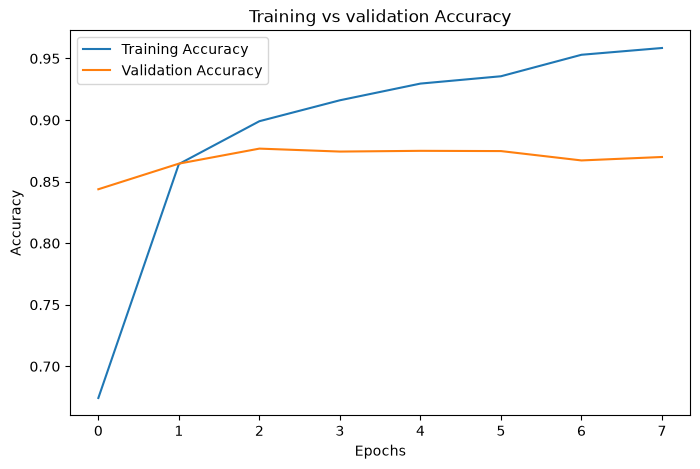

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.plot(history.history["accuracy"],label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Training vs validation Accuracy")

plt.legend()
plt.plot()

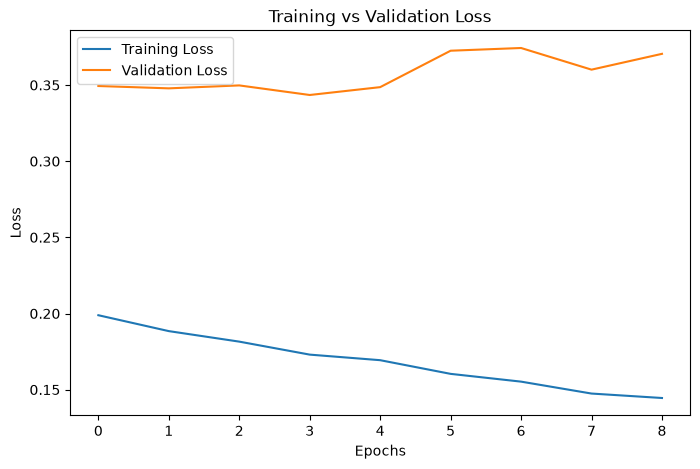

In [79]:
plt.figure(figsize=(8,5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")

plt.legend()
plt.show()

In [13]:
test_loss, test_accuracy = model.evaluate(X_test_pad, y_test)

782/782 ━━━━━━━━━━━━━━━━━━━━ 12s 16ms/step - accuracy: 0.8681 - loss: 0.3237


In [14]:
print(f"test loss: {test_loss}")
print(f"test accuracy: {test_accuracy}")

test loss: 0.32371798157691956
test accuracy: 0.868120014667511


In [15]:
y_probability = model.predict(X_test_pad)
y_pred = (y_probability >= 0.5).astype(int)

782/782 ━━━━━━━━━━━━━━━━━━━━ 12s 15ms/step


In [16]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)


print(f"Accuracy: {accuracy_score(y_test, y_pred)}")
print(f"Precission: {precision_score(y_test, y_pred)}")
print(f"Recall: {recall_score(y_test, y_pred)}")
print(f"F1 score: {f1_score(y_test, y_pred)}")
print(classification_report(y_test, y_pred, target_names=["Negative", "Positive"]))

Accuracy: 0.86812
Precission: 0.8756633194546494
Recall: 0.85808
F1 score: 0.8667824962624753
              precision    recall  f1-score   support

    Negative       0.86      0.88      0.87     12500
    Positive       0.88      0.86      0.87     12500

    accuracy                           0.87     25000
   macro avg       0.87      0.87      0.87     25000
weighted avg       0.87      0.87      0.87     25000



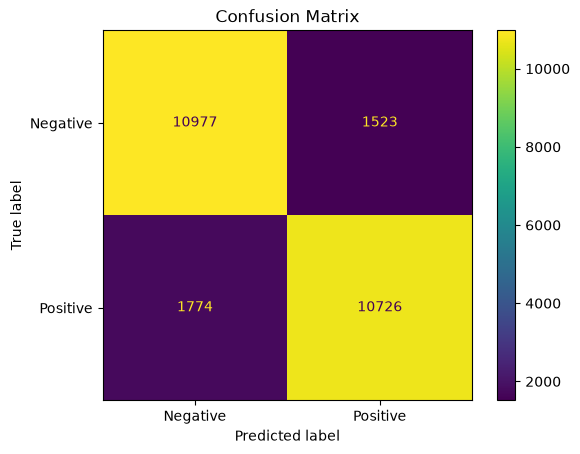

In [17]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)

display.plot()
plt.title("Confusion Matrix")

plt.show()

In [18]:
from tensorflow.keras.preprocessing.text import text_to_word_sequence
from tensorflow.keras.preprocessing.sequence import pad_sequences

word_index = imdb.get_word_index()

def preprocess_review(review):

    # Tokenize the review
    words = text_to_word_sequence(review)

    # Convert words into integer IDs
    encoded_review = [1] # 1 represents the IMDB start token.

    for word in words:
        
        index = word_index.get(word, 2) # 2 represents an unknown word.

        # Acccount for IMDB reserved indices

        if index + 3 < VOCAB_SIZE:
            encoded_review.append(index + 3) # Original vocabulary indices are shifted by 3. 0 is reserved for padding.
        else:
            encoded_review.append(2)

    # Apply padding
    padded_review = pad_sequences(
        [encoded_review],
        maxlen=MAX_LENGTH,
        padding="post",
        truncating="post"
    )

    return padded_review



def predict_sentiment(review):
    
    processed_review = preprocess_review(review)

    probability = model.predict(
        processed_review,
        verbose=0
    )[0][0]

    if probability >= 0.5:
        sentiment = "Positve"
    else:
        sentiment = "Negative"

    print("Review: ", review)
    print("Sentiment: ", sentiment)


In [19]:
review = """
The moview was fantastic.
The acting was excellent and the story was amazing.
"""

predict_sentiment(review)

Review:  
The moview was fantastic.
The acting was excellent and the story was amazing.

Sentiment:  Positve


In [20]:
predict_sentiment(
    "The movie was boring and the acting was terrible."
)

predict_sentiment(
    "I absolutely loved this movie. It was brilliant."
)

predict_sentiment(
    "The story was predictable, but the acting was excellent."
)

Review:  The movie was boring and the acting was terrible.
Sentiment:  Negative
Review:  I absolutely loved this movie. It was brilliant.
Sentiment:  Positve
Review:  The story was predictable, but the acting was excellent.
Sentiment:  Positve


In [21]:
model.save("imdb_sentiment_lstm.keras")